<a href="https://colab.research.google.com/github/johnmichaels4867-create/ACCTG5150/blob/main/Lab_3_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
df = pd.read_excel("CompustatAnnual_subset-for-lab3.xlsx")

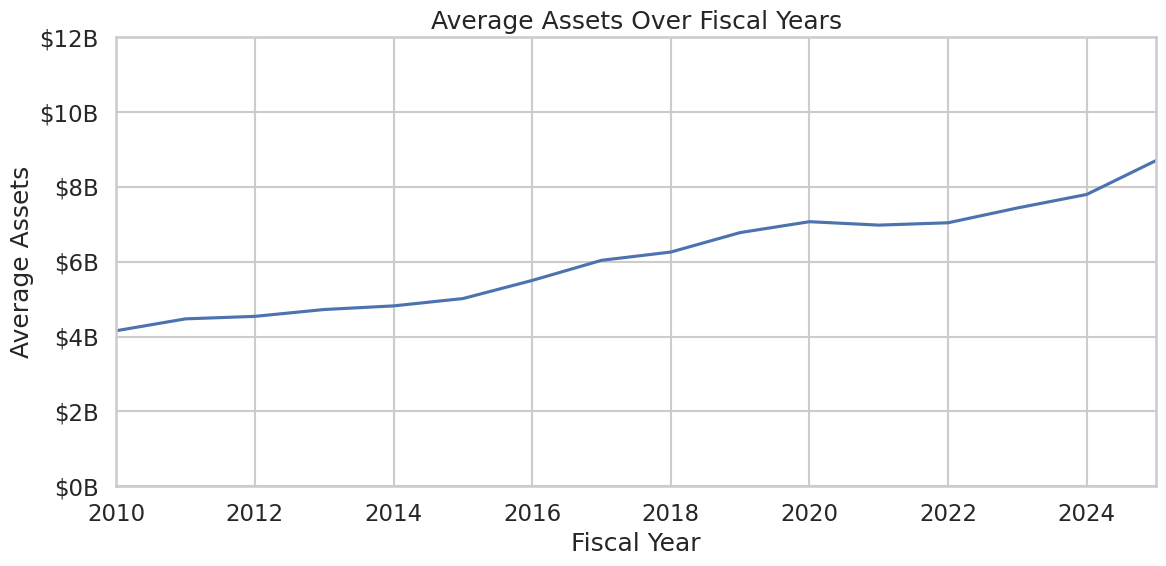

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 6)) # Adjust width and height as needed to make it longer
sns.lineplot(data=df, x='fyear', y='at', errorbar=None)
plt.ylim(0, 12000) # Set y-axis limit from 0 to 12 billion (assuming 'at' is in millions)

max_fyear = df['fyear'].max() # Get the maximum fiscal year from the DataFrame
plt.xlim(2010, max_fyear) # Set x-axis limit from 2010 to the maximum fiscal year

plt.xlabel('Fiscal Year')
plt.ylabel('Average Assets')
plt.title('Average Assets Over Fiscal Years') # Add a title to the graph

# Set y-axis ticks to increment by 2 billion
major_yticks = range(0, 12001, 2000)
plt.yticks(major_yticks)

# Set x-axis ticks to increment by 2 years, ending at or just after max_fyear
major_xticks = range(2010, max_fyear + 1, 2)
plt.xticks(major_xticks)

# Format y-axis labels to show '$XX B'
formatter = FuncFormatter(lambda x, pos: f'${int(x/1000)}B') # Divide by 1000 to convert millions to billions
plt.gca().yaxis.set_major_formatter(formatter)
plt.tight_layout() # Adjust layout to prevent labels from overlapping

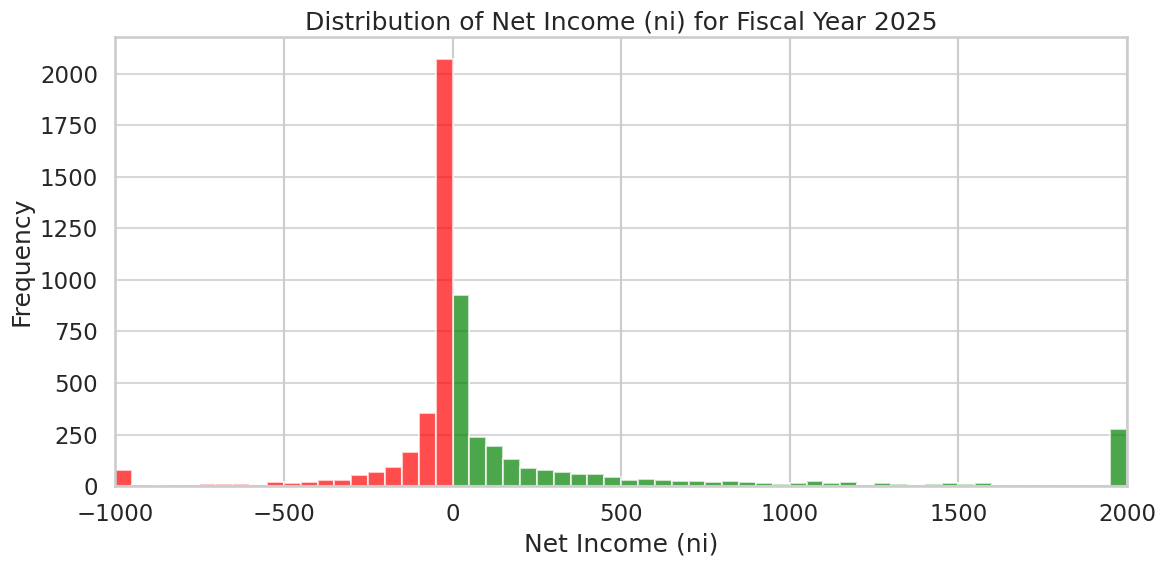

In [ ]:
import matplotlib.pyplot as plt

# Okay, this is unecessary red/green coloring of positive/negative values,
# but I want to show how easily you can make slick visualizations with python
plt.figure(figsize=(12, 6)) # Make the figure longer (wider)
ax = df.query("fyear==2025 & ni >= 0").ni.clip(upper=2000).hist(bins=range(0, 2001, 50), color='green', alpha=0.7)
df.query("fyear==2025 & ni < 0").ni.clip(lower=-1000).hist(bins=range(-1000, 1, 50), color='red', alpha=0.7, ax=ax)

# Find the maximum height (frequency) among all bars
max_height = 0
for patch in ax.patches:
    max_height = max(max_height, patch.get_height())

# Set y-axis limit to end at the highest bar with a small padding
padding = max_height * 0.05  # 5% padding
ax.set_ylim(bottom=0, top=max_height + padding)

# Set x-axis limit as requested
ax.set_xlim(-1000, 2000)

ax.set_title('Distribution of Net Income (ni) for Fiscal Year 2025')
ax.set_xlabel('Net Income (ni)')
ax.set_ylabel('Frequency')
ax.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

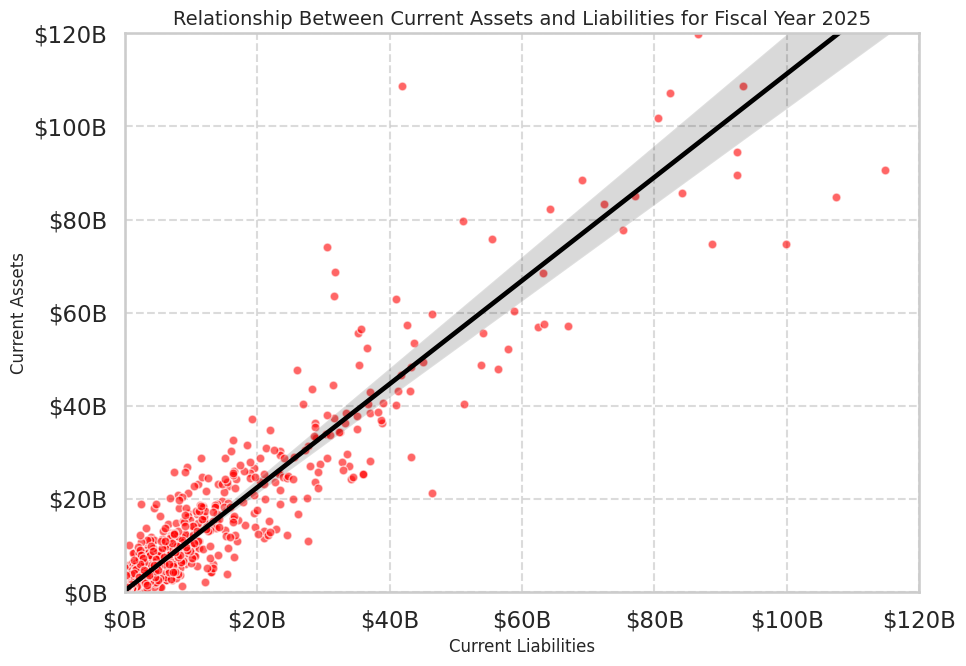

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Filter data for fyear 2025
df_2025 = df.query("fyear == 2025")

plt.figure(figsize=(10, 7)) # Adjust figure size for better readability
# Create the scatter plot with a regression line and refined aesthetics
sns.regplot(data=df_2025, x='lct', y='act', scatter_kws={'alpha':0.6, 'color':'red', 's':40, 'edgecolor':'white'}, line_kws={'color':'black'})

plt.title('Relationship Between Current Assets and Liabilities for Fiscal Year 2025', fontsize=14) # More descriptive title
plt.xlabel('Current Liabilities', fontsize=12)
plt.ylabel('Current Assets', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7) # Add a grid for easier value estimation

# Set x and y-axis limits to 0 to 120000 (representing 0B to 120B)
plt.xlim(0, 120000)
plt.ylim(0, 120000)

# Define ticks at intervals of 20000 for both axes
major_ticks = range(0, 120001, 20000)
plt.xticks(major_ticks)
plt.yticks(major_ticks)

# Format axis labels to show '$XX B'
formatter = FuncFormatter(lambda x, pos: f'${int(x/1000)}B')
plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

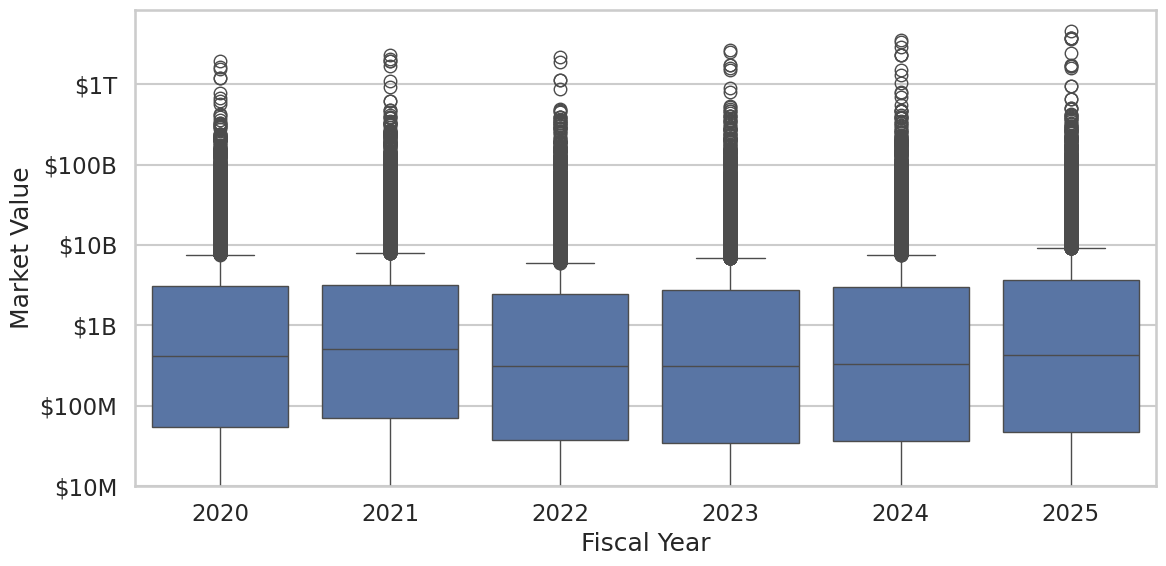

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.figure(figsize=(12, 6)) # Increased width for a wider plot, height remains the same
ax = sns.boxplot(data=df.query("fyear>=2020"), x="fyear", y="mve")
ax.set_yscale('log')
ax.set_ylim(bottom=10)
ax.set_xlabel('Fiscal Year')
ax.set_ylabel('Market Value')

y_ticks = [10, 100, 1000, 10000, 100000, 1000000] # Assuming mve is in millions
y_labels = ['$' + str(int(t)) + 'M' if t < 1000 else '$' + str(int(t/1000)) + 'B' if t < 1000000 else '$' + str(int(t/1000000)) + 'T' for t in y_ticks]

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)

plt.tight_layout()
plt.show()